# 5. Choosing λ: cross-validation for time series

The penalty must be chosen from the data, without using the data you will be judged on.

**Learning goals**: k-fold CV, why shuffled CV leaks with time series, blocked (forward-chaining) CV,
the one-standard-error rule, and information criteria.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(42)

## Shuffled k-fold leaks information in time series
If observations are autocorrelated, a randomly held-out quarter has its neighbours in the training
folds, so validation error is too optimistic and favours small penalties (overfitting).
Below: an AR(1)-style target where an irrelevant trending predictor looks useful under shuffled CV.

In [2]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
n, p = 120, 60
e = np.zeros(n)
for t in range(1, n): e[t] = 0.9 * e[t-1] + rng.normal()
X = np.cumsum(rng.normal(size=(n, p)), axis=0) * 0.1 + rng.normal(size=(n, p))  # persistent, irrelevant
y = e
res = {}
for name, cv in {"shuffled 5-fold": KFold(5, shuffle=True, random_state=0),
                 "forward-chaining 5-fold": TimeSeriesSplit(5)}.items():
    res[name] = [-cross_val_score(Ridge(alpha=a), X, y, cv=cv, scoring="neg_mean_squared_error").mean()
                 for a in np.logspace(-2, 4, 25)]
    print(f"{name:25s} chooses lambda = {np.logspace(-2, 4, 25)[int(np.argmin(res[name]))]:.2f},"
          f" min CV MSE = {min(res[name]):.2f}")
print("true out-of-sample MSE of the mean forecast is about", round(np.var(y), 2))

shuffled 5-fold           chooses lambda = 100.00, min CV MSE = 1.76


forward-chaining 5-fold   chooses lambda = 56.23, min CV MSE = 3.07
true out-of-sample MSE of the mean forecast is about 3.06


Shuffled CV reports an error well below what is achievable from irrelevant predictors and chooses a
small penalty. Forward-chaining CV, where each fold trains on the past and validates on the next
block, gives an honest estimate.

## What this project does
`nowcast.models.time_folds(n)` creates up to 5 expanding-window folds, each validating on the next
block of about n/8 quarters, so tuning never uses the future. The same folds are used for every model.

In [3]:
from nowcast.models import time_folds
for tr, va in time_folds(60):
    print(f"train rows {tr[0]:>2}-{tr[-1]:>2}   validate rows {va[0]}-{va[-1]}")

train rows  0-24   validate rows 25-31
train rows  0-31   validate rows 32-38
train rows  0-38   validate rows 39-45
train rows  0-45   validate rows 46-52
train rows  0-52   validate rows 53-59


## The one-standard-error rule
CV error curves are flat near the minimum. Choosing the largest $\lambda$ whose CV error is within one
standard error of the minimum gives a simpler model with almost the same expected accuracy.

min CV  lambda=0.166  non-zero=6
1-SE    lambda=0.235  non-zero=4


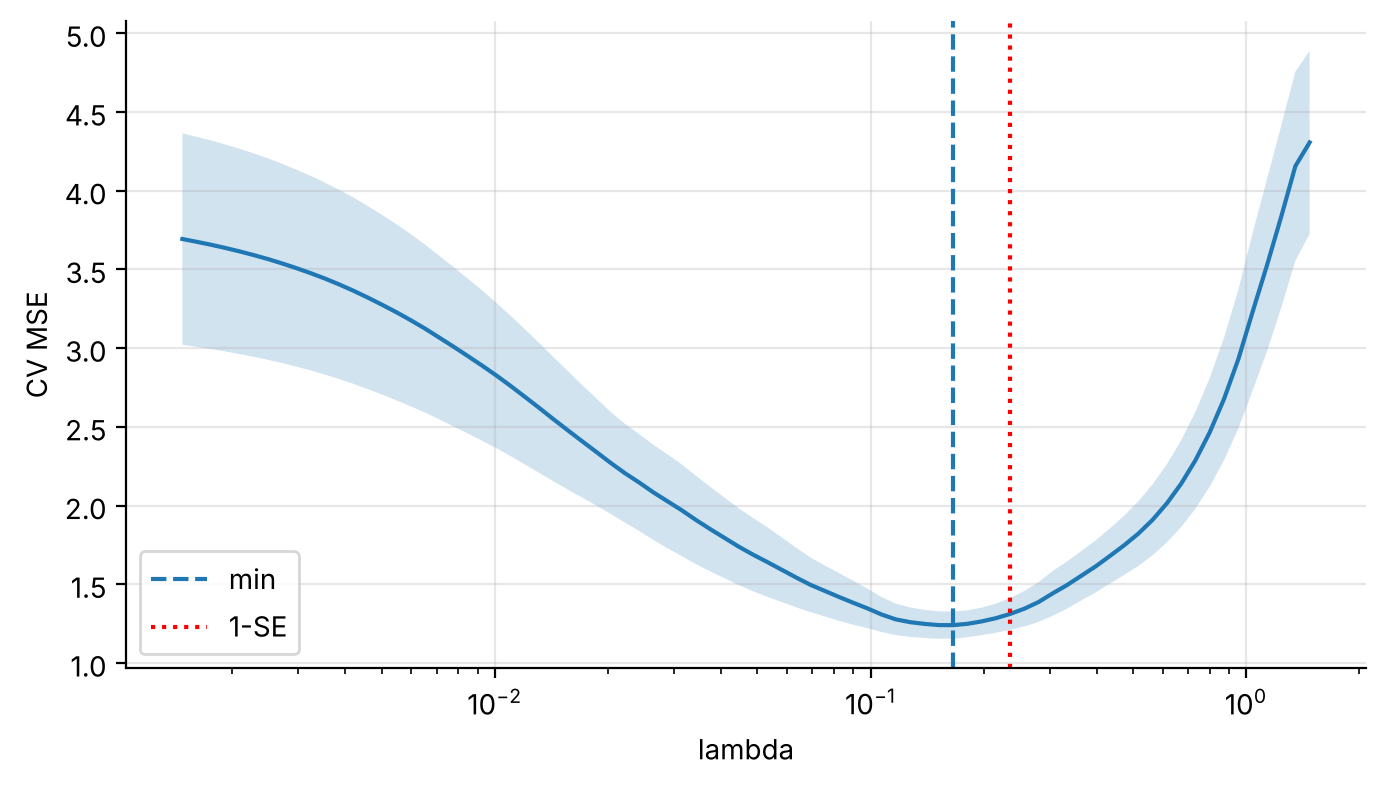

In [4]:
from sklearn.linear_model import LassoCV
n, p = 100, 50
X = rng.normal(size=(n, p)); y = X[:, :3] @ np.array([1, -1, 0.5]) + rng.normal(size=n)
m = LassoCV(cv=5, alphas=80).fit(X, y)
mean, se = m.mse_path_.mean(1), m.mse_path_.std(1) / np.sqrt(m.mse_path_.shape[1])
k = int(np.argmin(mean)); thr = mean[k] + se[k]
lam_1se = m.alphas_[np.where(mean <= thr)[0].min()]   # alphas_ sorted large -> small
from sklearn.linear_model import Lasso
for lab, lam in [("min CV", m.alpha_), ("1-SE", lam_1se)]:
    print(f"{lab:7s} lambda={lam:.3f}  non-zero={np.sum(Lasso(alpha=lam).fit(X, y).coef_ != 0)}")
plt.semilogx(m.alphas_, mean); plt.fill_between(m.alphas_, mean - se, mean + se, alpha=0.2)
plt.axvline(m.alpha_, ls="--", label="min"); plt.axvline(lam_1se, ls=":", c="r", label="1-SE")
plt.xlabel("lambda"); plt.ylabel("CV MSE"); plt.legend();

## Information criteria
For the lasso, the number of non-zero coefficients is an unbiased estimate of its degrees of freedom
(Zou, Hastie and Tibshirani, 2007), so AIC/BIC can choose $\lambda$ without refitting
(`LassoLarsIC`). BIC is fast and often picks sparser models, but it relies on an estimate of the noise
variance, which is unreliable when $p > n$. This project uses CV.

**Key takeaways**
* Never shuffle time series in CV.
* Tune inside every backtest origin, using only data available at that origin.
* The 1-SE rule trades a sliver of fit for parsimony.